# 02 - Training & Evaluation
This notebook documents how every model was trained, tuned and evaluated, and discusses the results. The heavy lifting lives in `ml/` and is run with `python -m ml.train`; here we load its artifacts and re-run the light parts.

**Algorithms used:** k-nearest neighbours (item, user, content), linear regression, logistic regression (sklearn + from scratch), decision tree, SVM, K-means.

In [1]:
import sys, json
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path('..').resolve(); ART = ROOT / 'artifacts'; PLOTS = ART / 'plots'
pd.set_option('display.precision', 4); pd.set_option('display.width', 200)

## 1. Train / validation / test split (no leakage)
Each user's ratings are sorted by time: oldest 80% train, next 10% validation, newest 10% test. Models therefore learn from a user's past and are scored on their future, which is how a deployed recommender is used. Validation is used only for early decisions (the hybrid weight); test is used once, at the end.

In [2]:
from ml.split import load_dataset
ds = load_dataset()
display(pd.Series({'train': len(ds.train), 'validation': len(ds.val), 'test': len(ds.test)}).to_frame('ratings'))
last_train = ds.train.groupby('u').timestamp.max()
first_test = ds.test.groupby('u').timestamp.min().reindex(last_train.index)
print('users whose training data is newer than their test data:', int((last_train > first_test).sum()))
unseen = ~ds.test.i.isin(ds.train.i.unique())
print(f'test ratings on movies never seen in training (cold items): {unseen.mean():.1%}')

,ratings
train,80650
validation,10093
test,10093


users whose training data is newer than their test data: 0
test ratings on movies never seen in training (cold items): 9.4%


## 2. The models in one paragraph each
* **Baselines** - global mean, user mean, item mean (damped), popularity (most rated), and the bias baseline `mu + b_u + b_i`. Anything 'intelligent' must beat these.
* **Item-kNN** - two movies are similar if the same users rated them similarly (cosine on rating residuals, shrunk when few users co-rated them). A user's score for a movie is a similarity-weighted average of their own ratings of its neighbours.
* **User-kNN** - the same idea across users: find the 100 users most like you.
* **Content-kNN** - movies become TF-IDF vectors of genres, tags and plot; neighbours come from cosine similarity, so new movies can be recommended without any ratings.
* **Hybrid** - `alpha * z(Item-kNN) + (1 - alpha) * z(Content-kNN)`, with alpha tuned on validation.
* **Linear / logistic regression, decision tree, SVM** - supervised models trained on a table of 15 features per (user, movie) pair: user and item means, popularity, the user's genre affinity, kNN and content scores and K-means segment statistics. Regressors predict the star rating, classifiers predict P(rating >= 4). They re-rank the top-200 Item-kNN candidates (two-stage recommendation).
* **K-means** - clusters users by genre taste; used as features and for cold start.

## 3. Hyper-parameter tuning
kNN models: grid search with 3-fold cross-validation on the training ratings (RMSE). Supervised models: `GridSearchCV` (3 folds) on out-of-fold training features (RMSE for regressors, ROC-AUC for classifiers).

In [3]:
grid = pd.read_csv(ART / 'tuning_grid_knn.csv')
for name, g in grid.groupby('model'):
    cols = [c for c in g.columns if c not in ('model', 'seconds') and g[c].notna().all()]
    print(f'{name}: best 4 settings by 3-fold CV RMSE')
    display(g[cols].sort_values('cv_rmse').head(4).reset_index(drop=True))
params = json.loads((ART / 'best_params.json').read_text())
print(json.dumps(params, indent=1))

content: best 4 settings by 3-fold CV RMSE


,k,cv_rmse
0,100,0.8991
1,20,0.8994
2,50,0.9015


item_knn: best 4 settings by 3-fold CV RMSE


,k,shrink,cv_rmse
0,80,10.0,0.8559
1,80,30.0,0.8578
2,40,10.0,0.8586
3,40,30.0,0.8597


user_knn: best 4 settings by 3-fold CV RMSE


,k,shrink,cv_rmse
0,100,5.0,0.8656
1,100,10.0,0.8659
2,50,10.0,0.8669
3,50,5.0,0.8670


{
 "knn": {
  "item_knn": {
   "k": 80,
   "shrink": 10
  },
  "user_knn": {
   "k": 100,
   "shrink": 5
  },
  "content": {
   "k": 100
  }
 },
 "supervised": {
  "Linear regression|reg": {},
  "Logistic regression|clf": {
   "m__C": 1
  },
  "Logistic regression (from scratch)|clf": {},
  "Decision tree|reg": {
   "m__max_depth": 6,
   "m__min_samples_leaf": 100
  },
  "Decision tree|clf": {
   "m__max_depth": 6,
   "m__min_samples_leaf": 100
  },
  "SVM|reg": {
   "m__C": 0.5
  },
  "SVM|clf": {
   "m__C": 0.1
  }
 }
}


### Hybrid weight on validation data
alpha = 1 is pure Item-kNN, alpha = 0 pure Content-kNN. Both curves peak in between, so the blend genuinely helps; the chosen alpha is the validation optimum.

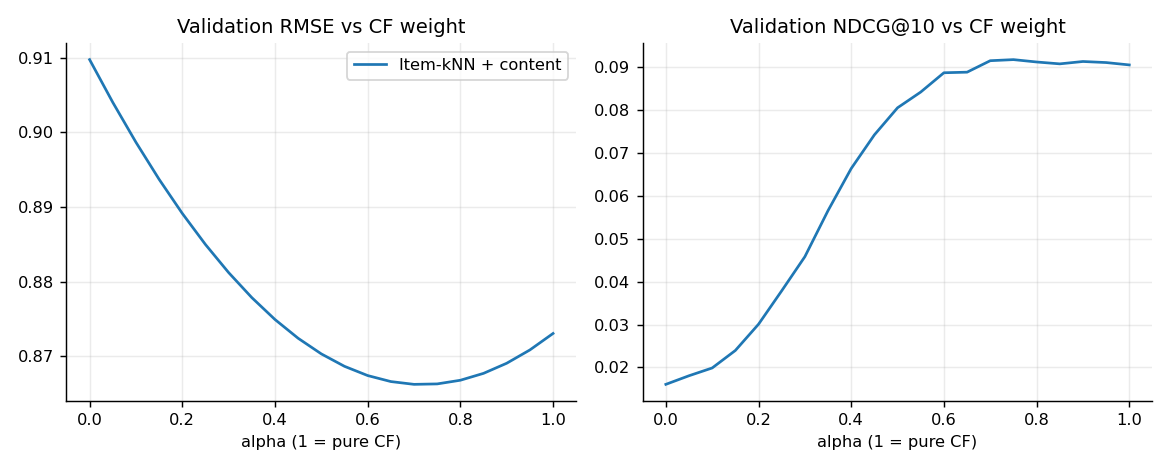

In [4]:
display(Image(PLOTS / 'alpha_curve.png'))

## 4. Test-set results
* **RMSE / MAE** - error of predicted star ratings (lower is better).
* **P@10, R@10, MAP@10, NDCG@10** - quality of the top-10 list; a hit is a test movie the user rated >= 4. NDCG rewards hits near the top.
* **Coverage** - share of the catalogue ever recommended; **Diversity** - how different the movies inside one list are; **Novelty** - how unpopular (surprising) they are.

In [5]:
res = pd.read_csv(ART / 'results.csv', index_col=0)
cols = ['RMSE', 'MAE', 'P@10', 'R@10', 'MAP@10', 'NDCG@10', 'Coverage', 'Diversity', 'Novelty', 'fit_s']
res[cols].sort_values('NDCG@10', ascending=False).style.format(precision=4).highlight_max(subset=['P@10', 'R@10', 'MAP@10', 'NDCG@10', 'Coverage', 'Diversity', 'Novelty'], color='#f6c3c0').highlight_min(subset=['RMSE', 'MAE'], color='#f6c3c0')

,RMSE,MAE,P@10,R@10,MAP@10,NDCG@10,Coverage,Diversity,Novelty,fit_s
model,,,,,,,,,,
Hybrid (Item-kNN + content),0.8620,0.6617,0.0520,0.0884,0.0462,0.0852,0.0794,0.7404,2.9755,2.4226
Item-kNN,0.8684,0.6673,0.0503,0.0875,0.0458,0.0840,0.0759,0.7746,2.9038,2.4013
User-kNN,0.8776,0.6785,0.0430,0.0778,0.0386,0.0714,0.0197,0.8167,1.6745,0.0159
Logistic regression (from scratch),nan,nan,0.0350,0.0579,0.0257,0.0527,0.0495,0.7524,2.9011,4.3957
Linear regression,0.8411,0.6451,0.0342,0.0564,0.0260,0.0526,0.0577,0.7438,2.8606,4.3957
Decision tree,0.8482,0.6487,0.0319,0.0540,0.0271,0.0526,0.0498,0.7843,2.5090,4.3957
SVM,0.8454,0.6384,0.0340,0.0506,0.0260,0.0514,0.0569,0.7536,3.0107,4.3957
Logistic regression,nan,nan,0.0338,0.0505,0.0259,0.0513,0.0572,0.7530,3.0001,4.3957
Popularity,0.9989,0.7769,0.0276,0.0476,0.0245,0.0472,0.0116,0.8037,1.4610,0.0009


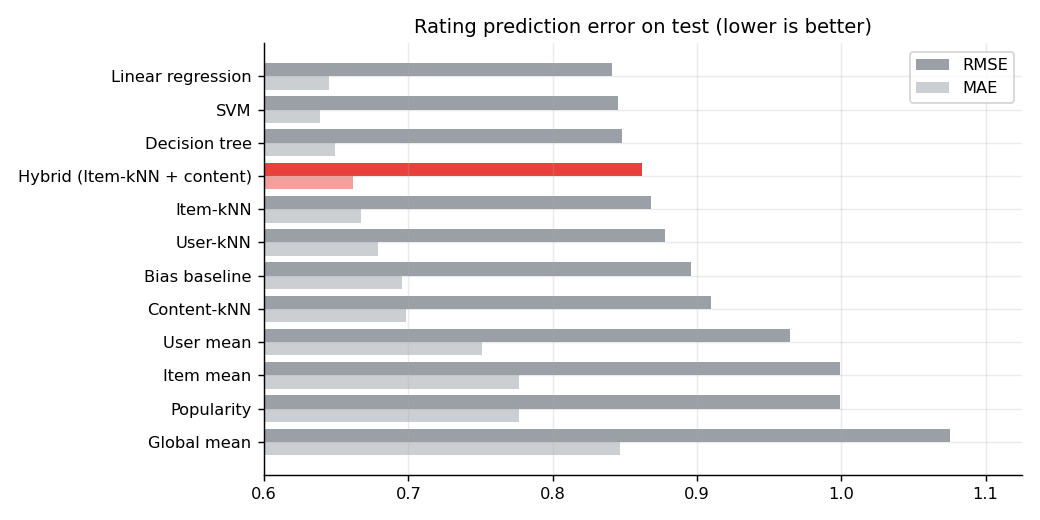

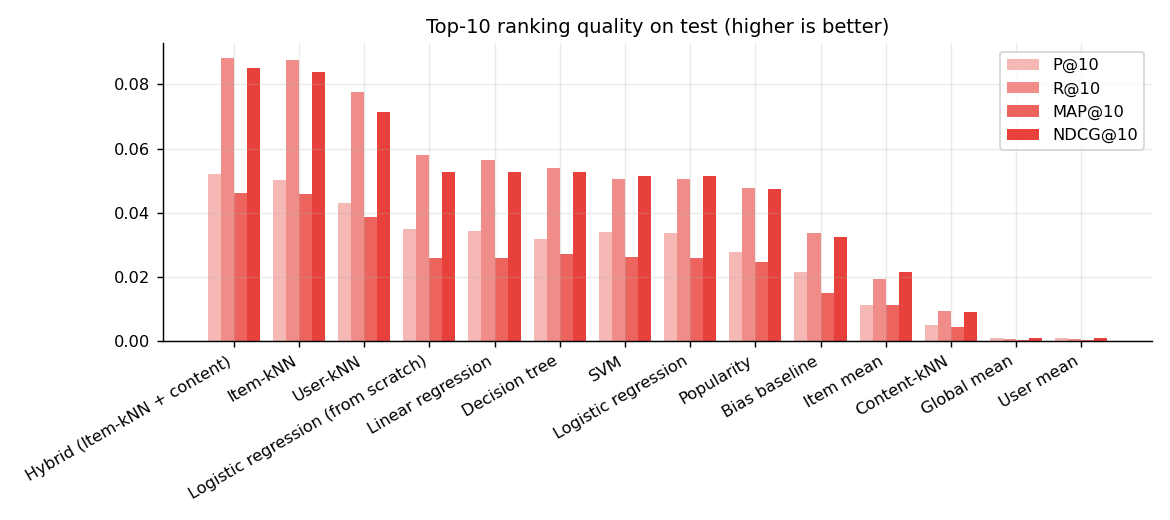

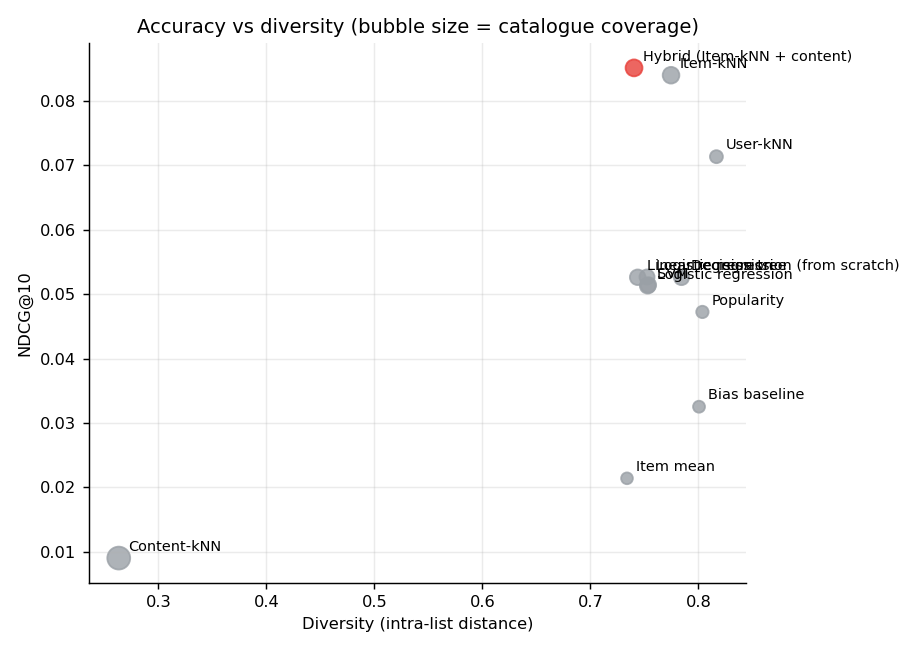

In [6]:
for p in ['accuracy.png', 'ranking.png', 'tradeoff.png']:
    display(Image(PLOTS / p))

## 5. Logistic regression from scratch vs scikit-learn
`ml/logreg_scratch.py` implements logistic regression with batch gradient descent (sigmoid, cross-entropy, L2 penalty). We rebuild the leakage-free feature table and compare it with scikit-learn on a held-out 20% of training pairs.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from ml.content import ContentModel
from ml.features import FEATURES, FeatureBuilder, build_training_set
from ml.logreg_scratch import LogisticRegressionScratch
serving = joblib.load(ART / 'serving.joblib')
content = ContentModel(ds.movies, ds.tags, k=int(params['knn']['content']['k']))
builder = FeatureBuilder(ds, content, params['knn'], serving['n_segments'])
X, y_rating, y_like = build_training_set(ds, ds.train, builder)
rng = np.random.default_rng(0); hold = rng.random(len(X)) < 0.2
scratch = LogisticRegressionScratch().fit(X[~hold], y_like[~hold])
sk = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X[~hold], y_like[~hold])
rows = {}
for name, m in [('from scratch', scratch), ('scikit-learn', sk)]:
    p = m.predict_proba(X[hold])[:, 1]
    rows[name] = {'ROC-AUC': roc_auc_score(y_like[hold], p), 'accuracy': accuracy_score(y_like[hold], p >= 0.5)}
display(pd.DataFrame(rows).T)
coef = pd.DataFrame({'from scratch': scratch.w, 'scikit-learn': sk[-1].coef_.ravel()}, index=FEATURES)
print('correlation of the two coefficient vectors:', round(coef.corr().iloc[0, 1], 3))
coef.sort_values('scikit-learn')

    OOF fold 1/4 done


    OOF fold 2/4 done


    OOF fold 3/4 done


    OOF fold 4/4 done


,ROC-AUC,accuracy
from scratch,0.8068,0.7263
scikit-learn,0.8068,0.7257


correlation of the two coefficient vectors: 0.763


,from scratch,scikit-learn
bias_pred,-0.1248,-1.1122
user_logn,-0.2684,-0.2525
item_logn,-0.1910,-0.1834
item_year,-0.0840,-0.0841
seg_mean,0.0276,-0.0392
uknn_rank,0.0371,0.0043
content_rank,0.0917,0.0883
seg_likes,0.0687,0.1222
content_pred,0.1127,0.1317
iknn_rank,0.2719,0.2337


**Why the predictions match but the coefficients differ.** Both models reach the same ROC-AUC, yet individual weights differ (e.g. `bias_pred` vs `user_mean` + `item_mean`). Those features are nearly linear combinations of each other (multicollinearity), so many different weight vectors give the same predictions; gradient descent stops after a fixed number of steps and settles on a different split of the weight than sklearn's L-BFGS solver. Interpret single coefficients with care.

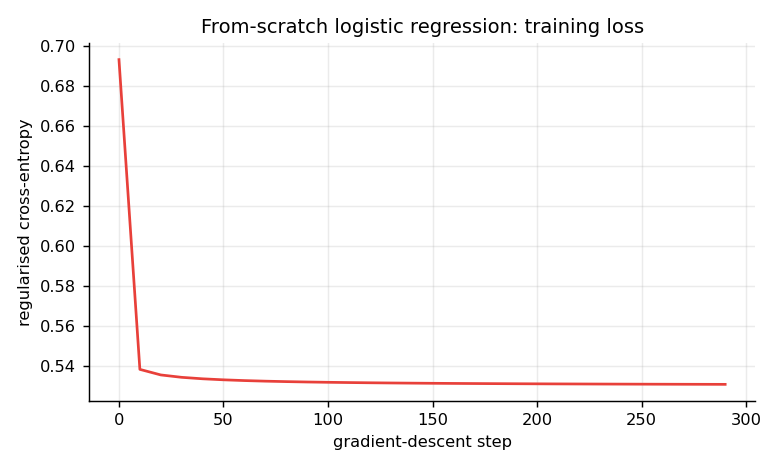

In [8]:
display(Image(PLOTS / 'logreg_scratch_loss.png'))

## 6. What the supervised models learned

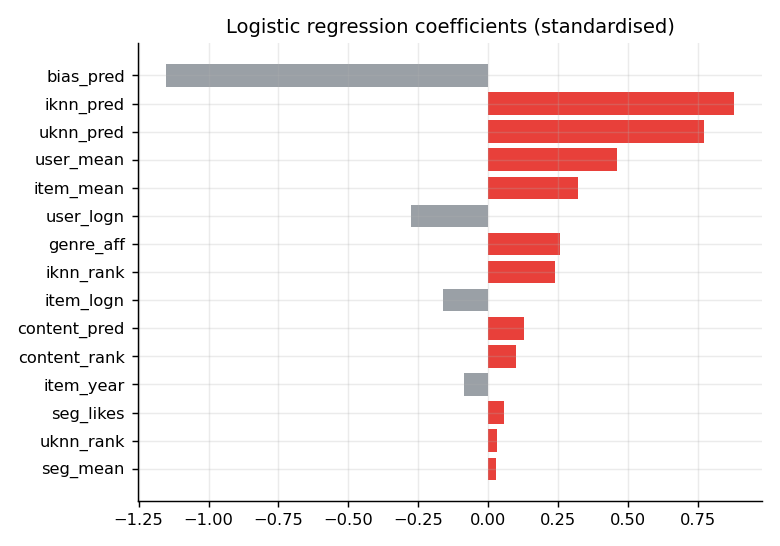

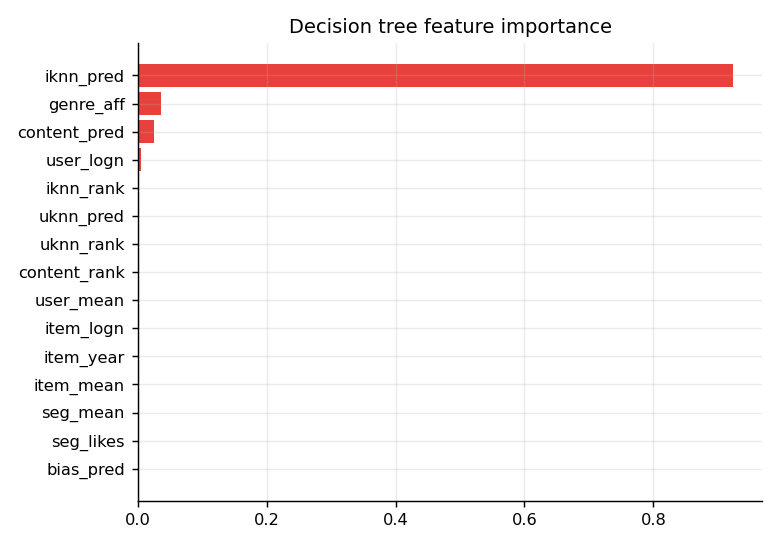

In [9]:
display(Image(PLOTS / 'logreg_coefficients.png')); display(Image(PLOTS / 'tree_importance.png'))

## 7. K-means taste segments
Users are described by the share of their ratings in each genre plus their mean rating. k was chosen by silhouette score. Low silhouette values mean the segments overlap: taste is a continuum rather than clean groups, so segments are coarse.

,users,mean rating,top genres
segment,,,
0,186,3.48,"Comedy, Drama, Action"
1,210,3.77,"Action, Adventure, Drama"
2,214,3.70,"Drama, Comedy, Thriller"


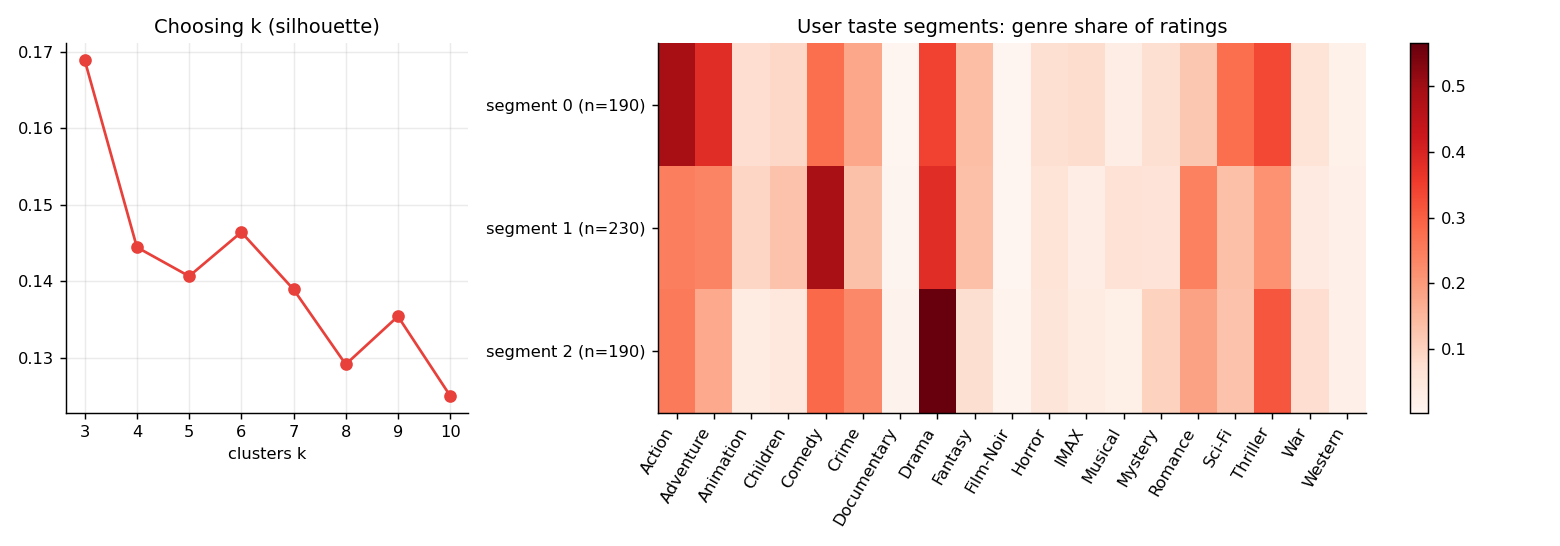

In [10]:
seg = serving['builder'].seg; names = serving['genre_names']
centers = pd.DataFrame(seg.km.cluster_centers_[:, :len(names)], columns=names)
summary = pd.DataFrame({
    'users': np.bincount(seg.labels_, minlength=seg.k),
    'mean rating': (seg.km.cluster_centers_[:, -1] * 5).round(2),
    'top genres': [', '.join(centers.loc[c].nlargest(3).index) for c in range(seg.k)],
})
summary.index.name = 'segment'
display(summary)
display(Image(PLOTS / 'segments.png'))

## 8. Cold start
**New users** keep only 5 liked movies (as if from onboarding). **New items** have all their ratings hidden from training, so only content can place them.

,NDCG@10,P@10,Coverage,Diversity
new_user,,,,
K-means segment,0.0528,0.0311,0.0151,0.7844
Popularity,0.0472,0.0277,0.0116,0.8035
Item-kNN,0.0409,0.0202,0.1370,0.7740
Segment + content,0.0389,0.0241,0.0452,0.5031
Content-kNN,0.0115,0.0068,0.2079,0.2587


,NDCG@10,P@10,Coverage,Diversity
new_item,,,,
Hybrid (Item-kNN + content),0.1102,0.0785,0.0231,0.5613
Content-kNN,0.1102,0.0785,0.0231,0.5613
User-kNN,0.0449,0.0288,0.0010,0.7339
Item-kNN,0.0449,0.0288,0.0010,0.7339
Random,0.0374,0.0297,0.0232,0.8149


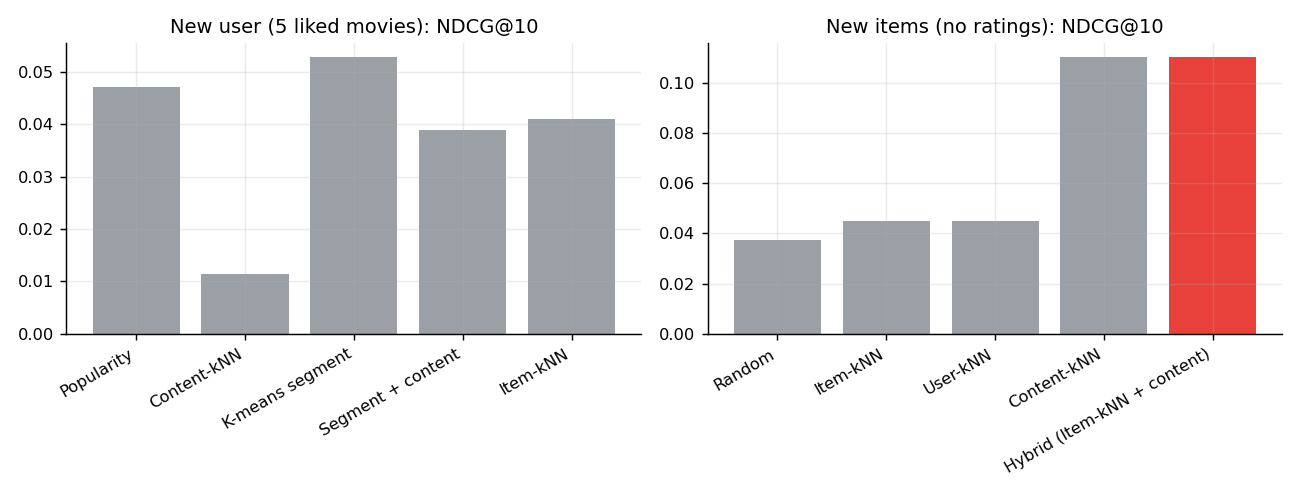

In [11]:
cold = json.loads((ART / 'cold_start.json').read_text())
for k in ['new_user', 'new_item']:
    t = pd.DataFrame({m: v for m, v in cold[k].items() if not m.startswith('_')}).T
    display(t[['NDCG@10', 'P@10', 'Coverage', 'Diversity']].sort_values('NDCG@10', ascending=False).rename_axis(k))
display(Image(PLOTS / 'cold_start.png'))

## 9. Explainability demo
A brand-new user loves *Toy Story*, *The Lion King* and *Finding Nemo* and hates *Saw*. Each model scores this rating row directly (no retraining). The hybrid's picks are explained by the liked movie most similar to each recommendation.

In [12]:
from scipy import sparse
idx = {m: i for i, m in enumerate(serving['item_ids'])}
titles = ds.movies.set_index('movieId')['clean_title']
picks = {1: 5.0, 364: 4.5, 6377: 5.0, 8957: 1.0}
row = sparse.csr_matrix((list(picks.values()), ([0] * 4, [idx[m] for m in picks])), shape=(1, len(idx)))
def top(model, k=5):
    _, r = model.score_rows(row); r = np.asarray(r).ravel().copy(); r[row.indices] = -np.inf
    return np.argsort(-r)[:k]
models = {'Popularity': serving['popularity'], 'Content-kNN': serving['content'],
          'Item-kNN': serving['item_knn'], 'Hybrid': serving['hybrid'],
          'Logistic regression': serving['feature_models']['Logistic regression']}
display(pd.DataFrame({n: [titles[serving['item_ids'][i]] for i in top(m)] for n, m in models.items()}))
for i in top(serving['hybrid']):
    why = serving['explainer'].because_you_liked(row, i, n=1)
    print(f"{titles[serving['item_ids'][i]]:35s} because you liked {titles[serving['item_ids'][why[0][0]]]} (sim {why[0][1]:.2f})")

,Popularity,Content-kNN,Item-kNN,Hybrid,Logistic regression
0,Forrest Gump,Aladdin,Aladdin,Aladdin,Aladdin
1,The Shawshank Redemption,Pete's Dragon,The Incredibles,The Incredibles,Toy Story 3
2,Pulp Fiction,Alice in Wonderland,"Monsters, Inc.",Toy Story 2,Toy Story 2
3,The Silence of the Lambs,A Bug's Life,Mrs. Doubtfire,"Monsters, Inc.",The Incredibles
4,The Matrix,Toy Story 2,Love Actually,Mrs. Doubtfire,Wallace & Gromit: The Wrong Trousers


Aladdin                             because you liked The Lion King (sim 0.48)
The Incredibles                     because you liked Finding Nemo (sim 0.48)
Toy Story 2                         because you liked Toy Story (sim 0.56)
Monsters, Inc.                      because you liked Toy Story (sim 0.48)
Mrs. Doubtfire                      because you liked Finding Nemo (sim 0.14)


## 10. Discussion
**Rating prediction vs ranking disagree.** The supervised models predict ratings best (linear regression has the lowest RMSE), yet the kNN hybrid produces the best top-10 lists. RMSE only scores movies the user actually rated, whereas ranking must pick 10 good movies out of ~9,700 unseen ones. The supervised models were trained only on rated pairs, so they never learned to tell 'rated and liked' from 'never chosen'; adding sampled unrated movies as negatives is the obvious next step.

**Accuracy vs diversity.** Popularity is a strong ranking baseline but recommends the same few blockbusters to everyone (tiny coverage, lowest novelty). Content-kNN has the highest coverage and novelty but very low intra-list diversity (it returns ten near-identical films) and weak accuracy. Collaborative models sit in between; the hybrid keeps Item-kNN's accuracy while borrowing some of content's reach.

**Sparsity.** The matrix is 98.3% empty and 62% of movies have fewer than five ratings, so neighbourhood similarities for tail items are noisy. Shrinkage and the bias baseline make kNN usable; content features cover the tail.

**Cold start.** Collaborative models cannot place unseen movies (near-random NDCG on the cold-item test) while Content-kNN more than doubles it. For new users with five picks, the K-means segment is the best single signal; blending it with content was worse on this metric, so the blend weight should be tuned on validation data.

**Scalability.** Item-kNN keeps only the top-k neighbours per movie (sparse matrix), so scoring a user is a sparse matrix product taking milliseconds. User-kNN must compare against every user at request time, which grows with the user base. The two-stage design (cheap candidate generation, expensive re-ranking of 200 items) is how production systems scale.

**Limitations.** One small dataset (610 users), a single temporal split, TMDB plot text missing without an API key, explicit ratings only, and offline metrics only (no A/B test).